Praktikum 3 - Splitting data (Titanic).

Tiga strategi: random split 8:1:1, stratified split 8:1:1, dan
k-fold cross validation (KFold 4, serta 80:20 + KFold pada data latih).
Output: output/*.png

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("splitting_data.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js03-ektraksi-fitur\praktikum-3


In [2]:
from pathlib import Path

import pandas as pd
import matplotlib

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold

HERE = Path(__file__).resolve().parent
DATA = HERE.parent / "data"
OUT = HERE / "output"
OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA / "Titanic-Dataset-selected.csv")

In [3]:
def ringkas(nama, d):
    vc = d["Survived"].value_counts().sort_index()
    r = vc / vc.sum()
    print(f"{nama:12s} n={len(d):4d} | 0={vc.get(0, 0):3d} 1={vc.get(1, 0):3d} "
          f"| rasio 0/1 = {r.get(0, 0):.3f}/{r.get(1, 0):.3f}")

1. RANDOM SPLIT (8:1:1)
Jumlah data asli : 891
Jumlah data train: 712
Jumlah data val  : 89
Jumlah data test : 90
asli         n= 891 | 0=549 1=342 | rasio 0/1 = 0.616/0.384
train        n= 712 | 0=439 1=273 | rasio 0/1 = 0.617/0.383
val          n=  89 | 0= 53 1= 36 | rasio 0/1 = 0.596/0.404
test         n=  90 | 0= 57 1= 33 | rasio 0/1 = 0.633/0.367

2. STRATIFIED SPLIT (8:1:1)
asli         n= 891 | 0=549 1=342 | rasio 0/1 = 0.616/0.384
train        n= 712 | 0=439 1=273 | rasio 0/1 = 0.617/0.383
val          n=  89 | 0= 55 1= 34 | rasio 0/1 = 0.618/0.382
test         n=  90 | 0= 55 1= 35 | rasio 0/1 = 0.611/0.389

3. CROSS VALIDATION 1 - KFold(4) pada seluruh data
Jumlah fold : 4
Obyek KFold : KFold(n_splits=4, random_state=None, shuffle=False)
Jumlah data : 891
fold 1: n_train=668 n_test=223 | train [223-890] test [0-222]
fold 2: n_train=668 n_test=223 | train [0-222, 446-890] test [223-445]
fold 3: n_train=668 n_test=223 | train [0-445, 669-890] test [446-668]
fold 4: n_train=669 n


grafik -> output/p3_proporsi_split.png

Selesai praktikum 3.


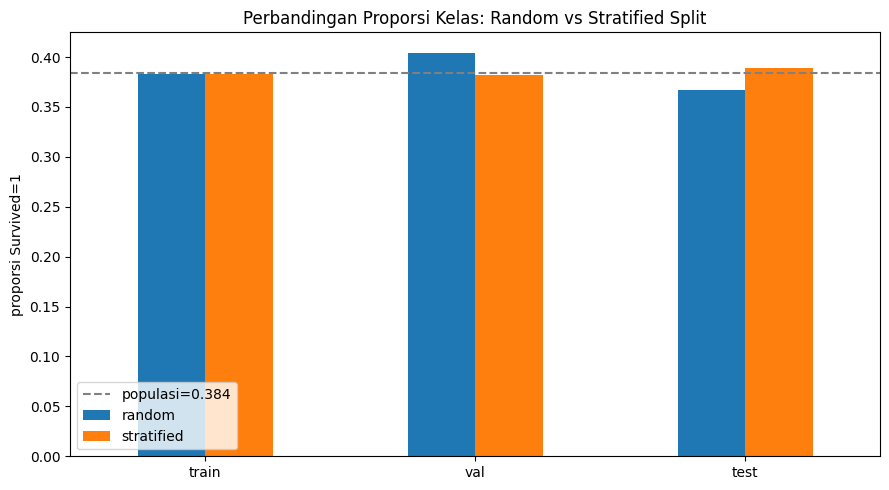

In [4]:
def idx_ranges(idx, n=6):
    """Ringkas index jadi rentang supaya tidak membanjiri stdout."""
    idx = list(idx)
    if not idx:
        return "[]"
    parts, start, prev = [], idx[0], idx[0]
    for i in idx[1:]:
        if i == prev + 1:
            prev = i
            continue
        parts.append(f"{start}-{prev}" if start != prev else f"{start}")
        start = prev = i
    parts.append(f"{start}-{prev}" if start != prev else f"{start}")
    return "[" + ", ".join(parts[:n]) + (" ...]" if len(parts) > n else "]")


# ============ 1. Random split 8:1:1 ============
print("=" * 60)
print("1. RANDOM SPLIT (8:1:1)")
X_tr, X_un = train_test_split(df, test_size=0.2, random_state=0)
X_val, X_te = train_test_split(X_un, test_size=0.5, random_state=0)
print(f"Jumlah data asli : {df.shape[0]}")
print(f"Jumlah data train: {X_tr.shape[0]}")
print(f"Jumlah data val  : {X_val.shape[0]}")
print(f"Jumlah data test : {X_te.shape[0]}")
ringkas("asli", df)
ringkas("train", X_tr)
ringkas("val", X_val)
ringkas("test", X_te)

# ============ 2. Stratified split 8:1:1 ============
print("\n" + "=" * 60)
print("2. STRATIFIED SPLIT (8:1:1)")
S_tr, S_un = train_test_split(df, test_size=0.2, random_state=0,
                              stratify=df["Survived"])
S_val, S_te = train_test_split(S_un, test_size=0.5, random_state=0,
                               stratify=S_un["Survived"])
ringkas("asli", df)
ringkas("train", S_tr)
ringkas("val", S_val)
ringkas("test", S_te)

# ============ 3. Cross validation 1: KFold 4 ============
print("\n" + "=" * 60)
print("3. CROSS VALIDATION 1 - KFold(4) pada seluruh data")
kf = KFold(n_splits=4)
print(f"Jumlah fold : {kf.get_n_splits()}")
print(f"Obyek KFold : {kf}")
print(f"Jumlah data : {df.shape[0]}")
for i, (tr, te) in enumerate(kf.split(df), 1):
    print(f"fold {i}: n_train={len(tr)} n_test={len(te)} "
          f"| train {idx_ranges(tr)} test {idx_ranges(te)}")

# ============ 4. Cross validation 2: split 80:20 + KFold ============
print("\n" + "=" * 60)
print("4. CROSS VALIDATION 2 - train_test_split(80:20) + KFold(4) pada train")
C_tr, C_te = train_test_split(df, test_size=0.2, random_state=0)
kf2 = KFold(n_splits=4)
print(f"Jumlah fold       : {kf2.get_n_splits()}")
print(f"Jumlah data train : {C_tr.shape[0]}")
print(f"Jumlah data test  : {C_te.shape[0]}")
for i, (tr, va) in enumerate(kf2.split(C_tr), 1):
    print(f"fold {i}: n_fit={len(tr)} n_val={len(va)} "
          f"| val {idx_ranges(C_tr.iloc[va].index)}")

# ============ 5. StratifiedKFold (pembanding tambahan) ============
print("\n" + "=" * 60)
print("5. TAMBAHAN - StratifiedKFold(4) pada data latih 80%")
skf = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)
for i, (tr, va) in enumerate(skf.split(C_tr, C_tr["Survived"]), 1):
    y = C_tr.iloc[va]["Survived"].value_counts().sort_index()
    print(f"fold {i}: n_fit={len(tr)} n_val={len(va)} | val 0={y.get(0, 0)} "
          f"1={y.get(1, 0)}")

# ============ visualisasi proporsi kelas ============
fig, ax = plt.subplots(figsize=(9, 5))
data = pd.DataFrame({
    "random": [X_tr["Survived"].mean(), X_val["Survived"].mean(),
               X_te["Survived"].mean()],
    "stratified": [S_tr["Survived"].mean(), S_val["Survived"].mean(),
                   S_te["Survived"].mean()],
}, index=["train", "val", "test"])
data.plot(kind="bar", ax=ax, rot=0)
ax.axhline(df["Survived"].mean(), ls="--", c="gray",
           label=f"populasi={df['Survived'].mean():.3f}")
ax.set_ylabel("proporsi Survived=1")
ax.set_title("Perbandingan Proporsi Kelas: Random vs Stratified Split")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "p3_proporsi_split.png", dpi=120)
print("\ngrafik -> output/p3_proporsi_split.png")
print("\nSelesai praktikum 3.")